## بارگذاری و تقسیم داده 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

In [2]:
url = "http://lib.stat.cmu.edu/datasets/boston"
raw_df = pd.read_csv(url, sep=r"\s+", skiprows=22, header=None)

feature_names = ["CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM", "AGE",
                 "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"]

X = pd.DataFrame(
    np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]]),
    columns=feature_names
)
y = pd.Series(raw_df.values[1::2, 2], name="MEDV")

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values:", X.isnull().sum().sum() + y.isnull().sum())
print("MEDV min/max:", y.min(), y.max())

X shape: (506, 13)
y shape: (506,)
Missing values: 0
MEDV min/max: 5.0 50.0


## آموزش و ارزیابی Random Forest 

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (404, 13) | Test: (102, 13)


In [4]:
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_train = rf.predict(X_train)
y_pred = rf.predict(X_test)

In [5]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_hat),
        "MAPE (%)": mean_absolute_percentage_error(y_true, y_hat) * 100,
        "R2": r2_score(y_true, y_hat),
    }

metrics_table = pd.DataFrame({
    "Train": regression_metrics(y_train, y_pred_train),
    "Test": regression_metrics(y_test, y_pred),
}).round(4)

display(metrics_table)

,Train,Test
MSE,1.9664,7.8802
RMSE,1.4023,2.8072
MAE,0.8986,2.0367
MAPE (%),4.5097,11.0866
R2,0.9774,0.8925



مدل با ۱۰۰ درخت آموزش دید. روی داده آزمون: RMSE برابر ___ ، MAE برابر ___ ، MAPE برابر ___٪ و R² برابر ___ است. R² آموزش (___) بسیار بالاتر از R² آزمون است که نشانه Overfitting معمول جنگل تصادفی است، ولی R² آزمون بالا نشان می‌دهد مدل بخش بزرگی از تغییرات قیمت را توضیح می‌دهد. RMSE بزرگ‌تر از MAE است، یعنی چند خطای بزرگ در پیش‌بینی‌ها وجود دارد.

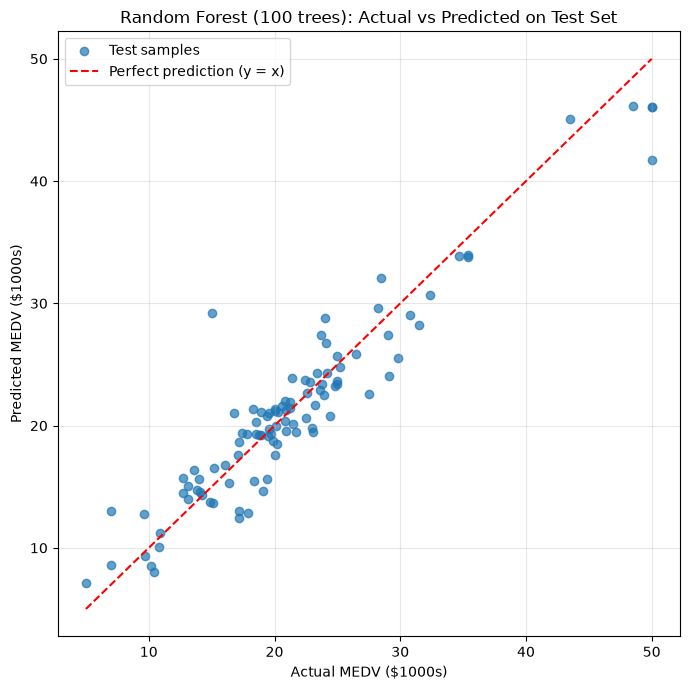

In [6]:
lo = min(y_test.min(), y_pred.min())
hi = max(y_test.max(), y_pred.max())

plt.figure(figsize=(7, 7))
plt.scatter(y_test, y_pred, alpha=0.7, label="Test samples")
plt.plot([lo, hi], [lo, hi], "r--", label="Perfect prediction (y = x)")
plt.xlabel("Actual MEDV ($1000s)")
plt.ylabel("Predicted MEDV ($1000s)")
plt.title("Random Forest (100 trees): Actual vs Predicted on Test Set")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## RMSE به دلار 

In [7]:
rows = []
for n in [50, 100, 200]:
    model = RandomForestRegressor(n_estimators=n, random_state=42, n_jobs=-1)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    rows.append({
        "Number of Trees": n,
        "Test RMSE ($1000s)": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R2": r2_score(y_test, pred),
    })

results_df = pd.DataFrame(rows).round(4)
display(results_df)

,Number of Trees,Test RMSE ($1000s),Test R2
0,50,2.7480,0.8970
1,100,2.8072,0.8925
2,200,2.9316,0.8828


,Number of Trees,Test RMSE ($1000s),Test R2,Test RMSE (USD)
0,50,2.7480,0.8970,2748.0
1,100,2.8072,0.8925,2807.2
2,200,2.9316,0.8828,2931.6


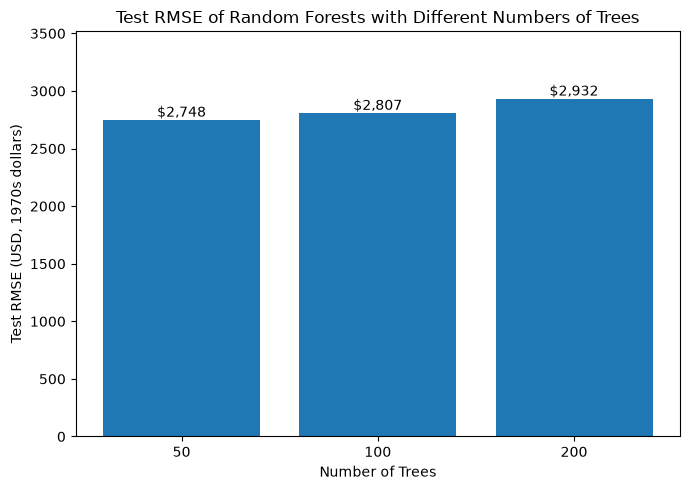

In [8]:
results_df["Test RMSE (USD)"] = results_df["Test RMSE ($1000s)"] * 1000
display(results_df)

plt.figure(figsize=(7, 5))
bars = plt.bar(results_df["Number of Trees"].astype(str),
               results_df["Test RMSE (USD)"])
plt.bar_label(bars, labels=[f"${v:,.0f}" for v in results_df["Test RMSE (USD)"]])
plt.xlabel("Number of Trees")
plt.ylabel("Test RMSE (USD, 1970s dollars)")
plt.title("Test RMSE of Random Forests with Different Numbers of Trees")
plt.ylim(0, results_df["Test RMSE (USD)"].max() * 1.2)
plt.tight_layout()
plt.show()


<div dir="rtl" style="text-align: right;">

### نتیجه‌گیری

در این تمرین، عملکرد الگوریتم **جنگل تصادفی (Random Forest Regressor)** برای پیش‌بینی قیمت خانه‌ها با استفاده از ۱۳ ویژگی و ۵۰۶ نمونه بررسی شد. داده‌ها به دو بخش آموزش و آزمون تقسیم شدند؛ به‌طوری‌که ۸۰ درصد داده‌ها برای آموزش و ۲۰ درصد برای ارزیابی مدل استفاده شدند.

مدل با ۱۰۰ درخت آموزش داده شد و نتایج ارزیابی نشان داد که مقدار ضریب تعیین (R²) برای داده‌های آموزش برابر با **۰٫۹۷۷۴** و برای داده‌های آزمون برابر با **۰٫۸۹۲۵** است. همچنین، مقدار خطای ریشه میانگین مربعات (RMSE) در داده‌های آزمون **۲٫۸۰۷۲**، میانگین قدرمطلق خطا (MAE) برابر با **۲٫۰۳۶۷** و درصد میانگین قدرمطلق خطا (MAPE) برابر با **۱۱٫۰۹ درصد** به دست آمد.

مقدار بالای R² در داده‌های آزمون نشان می‌دهد که مدل توانسته است بخش زیادی از تغییرات قیمت خانه‌ها را توضیح دهد. بااین‌حال، اختلاف میان عملکرد مدل در داده‌های آموزش و آزمون می‌تواند نشانه‌ای از بیش‌برازش (Overfitting) باشد.

همچنین، نمودار مقایسه مقادیر واقعی و پیش‌بینی‌شده نشان می‌دهد که بیشتر پیش‌بینی‌ها به خط ایده‌آل نزدیک هستند؛ هرچند در برخی نمونه‌ها اختلاف میان مقدار واقعی و پیش‌بینی‌شده مشاهده می‌شود.

 نتایج نشان داد که مدل با ۵۰ درخت، با مقدار RMSE برابر با **۲٫۷۴۸۰** و R² برابر با **۰٫۸۹۷۰**، بهترین عملکرد را در میان سه حالت بررسی‌شده داشته است. با افزایش تعداد درخت‌ها به ۱۰۰ و ۲۰۰، عملکرد مدل در مجموعه آزمون بهبود پیدا نکرد.

در مجموع، نتایج نشان می‌دهد که الگوریتم جنگل تصادفی عملکرد مناسبی در پیش‌بینی قیمت خانه‌ها داشته است؛ اما افزایش تعداد درخت‌ها لزوماً باعث بهبود دقت مدل نمی‌شود و انتخاب تعداد مناسب درخت‌ها باید بر اساس نتایج ارزیابی روی داده‌های آزمون انجام گیرد.

</div>
